# Decode: TPOT vs prompt length

1. Prefill results
2. Experiment design (shared by all models)
3. Qwen3-4B
   - Time at token k is linear in k
   - Intercept matches the prefill experiment
   - TPOT grows with prompt length
   - Total time: prefill vs decode
4. Gemma 4 E2B
   - Time at token k is linear in k
   - Intercept matches the prefill experiment
   - TPOT grows with prompt length: β 7× smaller than Qwen3-4B
5. Gemma 4 E2B vs Qwen3-4B
6. Notes: run-to-run variation
7. TODO

## Prefill results (from [`prefill_ttft.ipynb`](prefill_ttft.ipynb))

- vllm-mlx, Apple M1 8 GB, 4-bit weights. Prompt length set by noise headlines, 1.4k–21k tokens.
- TTFT stamped at token 2 (`prefill_only: true`, `max_tokens: 2`): prefill + 1 decode step.
- Fit `t = b·n + c·n²` (b: weight matmuls, c: attention):

| Model | b (ms/token) | c (µs/token²) | n* = b/c |
|---|---|---|---|
| Qwen3-4B | 6.2 | 0.21 | ~30k |
| Gemma 4 E2B | 0.86 | 0.009 | ~96k |

- WMT and AMZN agree within 1.6%: time depends on token count, not content.

This notebook measures the decode term and checks it against the prefill fit.

## Experiment design

Shared by all models. Same data, prompt, server and settings as the prefill experiment. Changes:

| | Prefill experiment | This experiment |
|---|---|---|
| `max_tokens` | 2 | 2, 16, 32, 64, 128 |
| Noise headlines | 50 … 1000 (AMZN 750) | 50, 100, 200, 300, 500, 750 |
| Prompt tokens (WMT) | 1.4k–21k | 1.4k–17k |

**Measurement**: streaming, `prefill_only: true`, `enable_thinking: true`. Each `max_tokens` value k is a separate request. Time stamped at the chunk carrying `finish_reason`: the arrival of token k. A row is valid only if `completion_tokens` ≥ k. The column is named `ttft_s`; here it is the time at token k. Concurrency 1, continuous batching off, prefix cache off, 1 warm-up, 3 repeats per point.

**Model**: prefill P(n) produces token 1; each further token is one decode step.

`t(n, k) = P(n) + (k − 1)·TPOT(n)`

Fit `t = s·k + i` at each n: slope s = TPOT(n), intercept i = P(n) − TPOT(n). TPOT also grows with the context during decode (n + j at step j); over k ≤ 128 this adds < 25 ms and is ignored.

## Qwen3-4B

`mlx-community/Qwen3-4B-4bit`.

| Ticker | Signal headlines | Data | Config |
|---|---|---|---|
| WMT | 10 | [`results/vllm-mlx/tpot-decode-baseline-qwen3-wmt.csv`](results/vllm-mlx/tpot-decode-baseline-qwen3-wmt.csv), run 2026-11-07T09:30 | [`configs/vllm-mlx/tpot-decode-baseline-qwen3-wmt.yaml`](configs/vllm-mlx/tpot-decode-baseline-qwen3-wmt.yaml) |
| AMZN | 7 | [`results/vllm-mlx/tpot-decode-baseline-qwen3-amzn.csv`](results/vllm-mlx/tpot-decode-baseline-qwen3-amzn.csv), run 2026-11-07T13:02 | [`configs/vllm-mlx/tpot-decode-baseline-qwen3-amzn.yaml`](configs/vllm-mlx/tpot-decode-baseline-qwen3-amzn.yaml) |

The WMT file also holds a later noise-100 recheck (run 12:49); excluded here.

### Time at token k is linear in k

Fit uses all 15 rows per prompt length (5 values of k × 3 repeats); ± is the standard error of the fit.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RUNS = {"WMT": ("results/vllm-mlx/tpot-decode-baseline-qwen3-wmt.csv", "2026-11-07T09:30:25"),
        "AMZN": ("results/vllm-mlx/tpot-decode-baseline-qwen3-amzn.csv", None)}


def line_fit(k, t):
    X = np.c_[k, np.ones_like(k)]
    coef = np.linalg.lstsq(X, t, rcond=None)[0]
    r = t - X @ coef
    se = np.sqrt(np.diag(r @ r / (len(t) - 2) * np.linalg.inv(X.T @ X)))
    return coef, se


def decode_fits(path, run_at):
    df = pd.read_csv(path)
    df = df[df.ok & (df.completion_tokens >= df.max_tokens) & ((df.run_at == run_at) if run_at else True)]
    rows = []
    for noise, g in df.groupby("noise_headlines"):
        (s, i), (s_se, i_se) = line_fit(g.max_tokens.to_numpy(float), g.ttft_s.to_numpy())
        rows.append({"noise": noise, "n": g.prompt_tokens.median(), "rows": len(g),
                     "tpot_ms": s * 1e3, "tpot_se_ms": s_se * 1e3, "intercept_s": i, "intercept_se_s": i_se})
    return df, pd.DataFrame(rows).set_index("noise")


data, tpot = {}, {}
for k, (p, run_at) in RUNS.items():
    data[k], tpot[k] = decode_fits(p, run_at)
pd.concat(tpot, names=["ticker"]).round(3)

n  rows  tpot_ms  tpot_se_ms  intercept_s  intercept_se_s
ticker noise                                                                 
WMT    50      1425.0    15   46.051       0.062        9.359           0.004
       100     2621.0    15   51.076       0.275       17.424           0.018
       200     5042.0    15   55.944       0.375       35.891           0.025
       300     7471.0    15   63.221       0.242       57.026           0.016
       500    11882.0    15   75.692       0.530      102.177           0.035
       750    17027.0    15   89.039       0.833      165.642           0.055
AMZN   50      1473.0    15   46.350       0.096        9.565           0.006
       100     2669.0    15   50.730       0.057       17.856           0.004
       200     5090.0    15   56.319       0.229       36.128           0.015
       300     7519.0    15   63.244       0.262       57.296           0.017
       500    11930.0    15   73.742       0.189      102.587           0.012
       750    17075.0    15   92.878       1.298      166.448           0.086

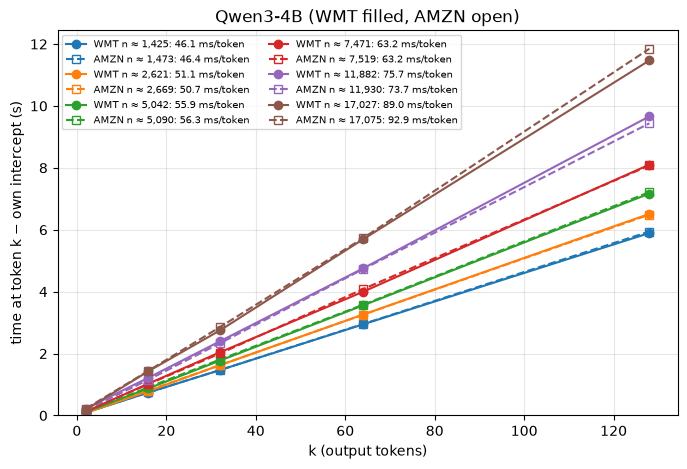

In [2]:
fig, ax = plt.subplots(figsize=(8, 5))
for i, noise in enumerate(tpot["WMT"].index):
    for tk, style in [("WMT", dict(marker="o", ls="-")), ("AMZN", dict(marker="s", ls="--", mfc="none"))]:
        row = tpot[tk].loc[noise]
        m = data[tk][data[tk].noise_headlines == noise].groupby("max_tokens").ttft_s.median()
        ax.plot(m.index, m - row.intercept_s, color=f"C{i}", label=f"{tk} n ≈ {row.n:,.0f}: {row.tpot_ms:.1f} ms/token", **style)
ax.set(title="Qwen3-4B (WMT filled, AMZN open)", xlabel="k (output tokens)", ylabel="time at token k − own intercept (s)", ylim=(0, None))
ax.grid(alpha=0.3)
ax.legend(fontsize=7, ncol=2);

### Intercept matches the prefill experiment

Both experiments stamp a time at token 2. From this experiment: `t(n, 2) = i + 2·s`. From the prefill experiment: `b·n + c·n²`, refitted below from its committed results. Separate runs, 6 days (AMZN) and 13 days (WMT) apart.

In [3]:
PREFILL = {"WMT": "results/vllm-mlx/ttft-prefill-baseline.csv", "AMZN": "results/vllm-mlx/ttft-prefill-baseline-amzn.csv"}


def prefill_fit(path):
    df = pd.read_csv(path).dropna(subset=["ttft_s"])
    m = df[df.ok].groupby("noise_headlines")[["prompt_tokens", "ttft_s"]].median()
    n, t = m.prompt_tokens.to_numpy(), m.ttft_s.to_numpy()
    return np.linalg.lstsq(np.c_[n, n**2] / t[:, None], np.ones_like(t), rcond=None)[0]


rows = []
for k, path in PREFILL.items():
    b, c = prefill_fit(path)
    for noise, r in tpot[k].iterrows():
        t2 = r.intercept_s + 2 * r.tpot_ms / 1e3
        pf = b * r.n + c * r.n**2
        rows.append({"ticker": k, "noise": noise, "n": r.n, "t2_decode_fit_s": t2, "prefill_fit_s": pf,
                     "diff_%": 100 * (t2 / pf - 1), "P_s": r.intercept_s + r.tpot_ms / 1e3})
pd.DataFrame(rows).set_index(["ticker", "noise"]).round(3)

n  t2_decode_fit_s  prefill_fit_s  diff_%      P_s
ticker noise                                                          
WMT    50      1425.0            9.451          9.240   2.280    9.405
       100     2621.0           17.526         17.642  -0.654   17.475
       200     5042.0           36.003         36.454  -1.238   35.947
       300     7471.0           57.152         57.759  -1.050   57.089
       500    11882.0          102.329        102.669  -0.332  102.253
       750    17027.0          165.820        165.192   0.380  165.731
AMZN   50      1473.0            9.657          9.540   1.233    9.611
       100     2669.0           17.957         17.940   0.098   17.907
       200     5090.0           36.241         36.740  -1.358   36.185
       300     7519.0           57.422         58.018  -1.026   57.359
       500    11930.0          102.735        102.845  -0.107  102.661
       750    17075.0          166.633        165.214   0.859  166.540

- The two experiments agree within −1.4% to +2.3% at the same prompt length. Run-to-run drift in the prefill experiment was 0.2–2%.
- `P_s` = i + s: prefill alone, time to token 1.

### TPOT grows with prompt length: the KV cache is read every step

Each decode step reads all weights and the whole KV cache.

| Per decode step | Bytes |
|---|---|
| Weights (`model.safetensors`, 4-bit + fp16 scales/biases; embeddings tied to the output projection, so read in full) | 2.1 GB |
| KV cache per context token: 36 layers × 8 KV heads × 128 × 2 (K, V) × 2 bytes | 144 KiB |

Model: `TPOT(n) = (W + n·kv) / BW_eff`, i.e. `a + β·n` with a = W / BW_eff, β = kv / BW_eff.

TPOT ≈ 42.4 ms + 2.80 µs·n
BW_eff from a: 50 GB/s   from β: 53 GB/s   M1 peak: ~68 GB/s


,ticker,noise,n,tpot_ms,bytes_GB,bw_eff_GB_s
0,WMT,50,1425.0,46.05,2.31,50.16
1,WMT,100,2621.0,51.08,2.49,48.68
2,WMT,200,5042.0,55.94,2.84,50.83
3,WMT,300,7471.0,63.22,3.20,50.64
4,WMT,500,11882.0,75.69,3.85,50.89
5,WMT,750,17027.0,89.04,4.61,51.78
6,AMZN,50,1473.0,46.35,2.32,49.99
7,AMZN,100,2669.0,50.73,2.49,49.15
8,AMZN,200,5090.0,56.32,2.85,50.61
9,AMZN,300,7519.0,63.24,3.21,50.74


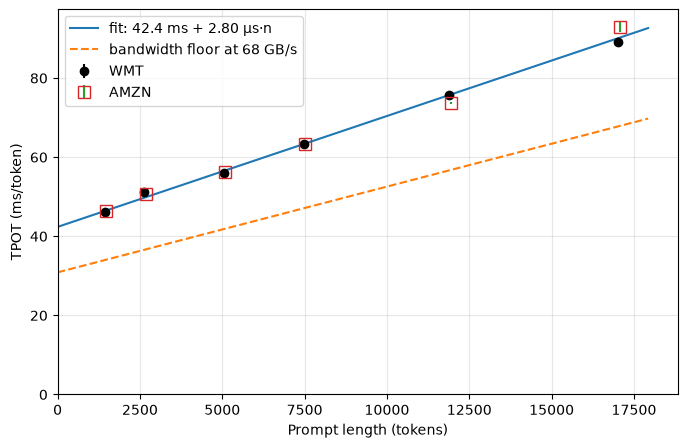

In [4]:
W, KV = 2.1e9, 36 * 8 * 128 * 2 * 2
both = pd.concat(tpot, names=["ticker"]).reset_index()
beta, a = np.polyfit(both.n, both.tpot_ms / 1e3, 1)
both["bytes_GB"] = (W + both.n * KV) / 1e9
both["bw_eff_GB_s"] = both.bytes_GB / (both.tpot_ms / 1e3)
print(f"TPOT ≈ {a * 1e3:.1f} ms + {beta * 1e6:.2f} µs·n")
print(f"BW_eff from a: {W / a / 1e9:.0f} GB/s   from β: {KV / beta / 1e9:.0f} GB/s   M1 peak: ~68 GB/s")

x = np.linspace(0, 1.05 * both.n.max(), 100)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, (a + beta * x) * 1e3, label=f"fit: {a * 1e3:.1f} ms + {beta * 1e6:.2f} µs·n")
ax.plot(x, W / 68e9 * 1e3 + KV / 68e9 * 1e3 * x, "--", label="bandwidth floor at 68 GB/s")
for (name, g), style in zip(both.groupby("ticker", sort=False), [dict(fmt="ko"), dict(fmt="s", mfc="none", mec="C3", ms=9)]):
    ax.errorbar(g.n, g.tpot_ms, yerr=g.tpot_se_ms, label=name, **style)
ax.set(xlabel="Prompt length (tokens)", ylabel="TPOT (ms/token)", xlim=(0, None), ylim=(0, None))
ax.grid(alpha=0.3)
ax.legend()
both[["ticker", "noise", "n", "tpot_ms", "bytes_GB", "bw_eff_GB_s"]].round(2)

- Weights dominate the bytes at 1.4k tokens; at 17k the KV cache (2.5 GB) exceeds the weights.
- Effective bandwidth is 49–52 GB/s at all lengths, ~75% of the 68 GB/s peak: decode is memory-bandwidth-bound.
- The intercept a implies 50 GB/s for the weight read and the slope β implies 53 GB/s for the KV read: both reads run at similar efficiency.
- The line fits all twelve points within 2.6 ms; the largest residuals are AMZN at 11.9k (−2.1 ms) and 17k (+2.6 ms). No curvature resolved.
- AMZN prompts are 48 tokens longer. AMZN matches WMT within 0.4 ms up to 7.5k tokens; at 11.9k and 17k the gaps are −2.0 and +3.8 ms, the size of the repeat-to-repeat spread at those lengths.

### Total time: prefill vs decode

`t(n, k) = P(n) + (k − 1)·TPOT(n)` with P(n) from the prefill fit and TPOT(n) from the fit above.

In [5]:
b, c = prefill_fit(PREFILL["WMT"])
rows = []
for n in [1_000, 5_000, 12_000, 20_000]:
    for k in [128, 512, 2048]:
        tp = a + beta * n
        P = b * n + c * n**2 - tp
        rows.append({"n": n, "k": k, "prefill_s": P, "decode_s": (k - 1) * tp, "total_s": P + (k - 1) * tp,
                     "prefill_%": 100 * P / (P + (k - 1) * tp)})
pd.DataFrame(rows).set_index(["n", "k"]).round(1)

prefill_s  decode_s  total_s  prefill_%
n     k                                            
1000  128         6.4       5.7     12.1       52.5
      512         6.4      23.1     29.4       21.6
      2048        6.4      92.5     98.8        6.4
5000  128        36.1       7.2     43.2       83.4
      512        36.1      28.8     64.9       55.6
      2048       36.1     115.4    151.5       23.8
12000 128       103.9       9.7    113.6       91.5
      512       103.9      38.8    142.8       72.8
      2048      103.9     155.6    259.5       40.0
20000 128       206.2      12.5    218.7       94.3
      512       206.2      50.3    256.5       80.4
      2048      206.2     201.5    407.7       50.6

- Extrapolated: k > 128 and n = 20k are outside this sweep. Ignores TPOT growth with k (adds β·k²/2: ~6 s at k = 2048).
- Prefill is more than half the total up to k ≈ 650 at n = 5k and k ≈ 1,400 at n = 12k.
- Prefill cost is per request and n-dependent; prefix caching removes it for a shared prefix. Decode cost is per token and mostly fixed by weight bytes.

## Gemma 4 E2B

`mlx-community/Gemma4-E2B-IT-Text-int4`. Prompts as in the Gemma prefill configs.

| Ticker | Signal headlines | Noise headlines | Data | Config |
|---|---|---|---|---|
| WMT | 10 | 50, 100, 200, 300, 500, 750, 1000 | [`results/vllm-mlx/tpot-decode-baseline-gemma4-e2b-wmt.csv`](results/vllm-mlx/tpot-decode-baseline-gemma4-e2b-wmt.csv), run 2026-11-07T15:28 | [`configs/vllm-mlx/tpot-decode-baseline-gemma4-e2b-wmt.yaml`](configs/vllm-mlx/tpot-decode-baseline-gemma4-e2b-wmt.yaml) |
| AMZN | 7 | 50, 100, 200, 300, 500, 750, 1000 | [`results/vllm-mlx/tpot-decode-baseline-gemma4-e2b-amzn.csv`](results/vllm-mlx/tpot-decode-baseline-gemma4-e2b-amzn.csv), run 2026-11-07T16:26 | [`configs/vllm-mlx/tpot-decode-baseline-gemma4-e2b-amzn.yaml`](configs/vllm-mlx/tpot-decode-baseline-gemma4-e2b-amzn.yaml) |

`completion_tokens` = k + 2 in every row, as in the Gemma prefill run. Constant offset: the slope is unaffected.

### Time at token k is linear in k

n  rows  tpot_ms  tpot_se_ms  intercept_s  intercept_se_s
ticker noise                                                                 
WMT    50      1426.0    15   26.889       0.022        1.203           0.001
       100     2604.0    15   27.319       0.029        2.253           0.002
       200     4978.0    15   28.390       0.016        4.443           0.001
       300     7361.0    15   29.538       0.092        6.740           0.006
       500    11643.0    15   30.970       0.059       11.183           0.004
       750    16573.0    15   32.848       0.164       16.755           0.011
       1000   20385.0    15   34.621       0.082       21.297           0.005
AMZN   50      1480.0    15   26.883       0.025        1.263           0.002
       100     2657.0    15   27.245       0.074        2.296           0.005
       200     5033.0    15   28.458       0.035        4.495           0.002
       300     7415.0    15   29.751       0.078        6.802           0.005
       500    11697.0    15   30.931       0.065       11.264           0.004
       750    16627.0    15   32.436       0.191       16.819           0.013
       1000   20440.0    15   34.491       0.272       21.389           0.018

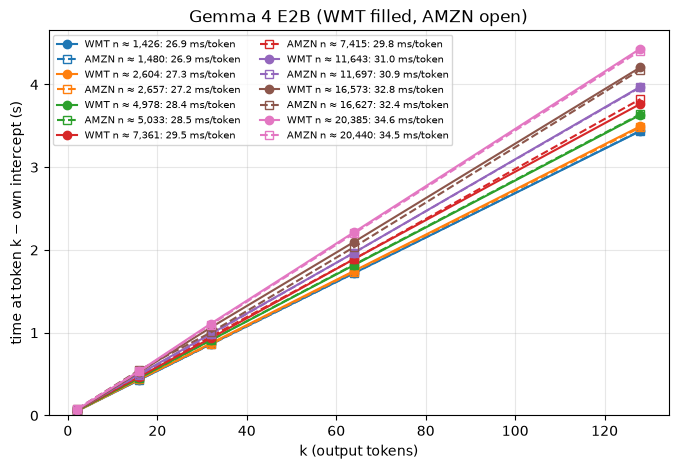

In [6]:
G_RUNS = {"WMT": ("results/vllm-mlx/tpot-decode-baseline-gemma4-e2b-wmt.csv", None),
          "AMZN": ("results/vllm-mlx/tpot-decode-baseline-gemma4-e2b-amzn.csv", None)}
g_data, g_tpot = {}, {}
for k, (p, run_at) in G_RUNS.items():
    g_data[k], g_tpot[k] = decode_fits(p, run_at)

fig, ax = plt.subplots(figsize=(8, 5))
for i, noise in enumerate(g_tpot["WMT"].index):
    for tk, style in [("WMT", dict(marker="o", ls="-")), ("AMZN", dict(marker="s", ls="--", mfc="none"))]:
        row = g_tpot[tk].loc[noise]
        m = g_data[tk][g_data[tk].noise_headlines == noise].groupby("max_tokens").ttft_s.median()
        ax.plot(m.index, m - row.intercept_s, color=f"C{i}", label=f"{tk} n ≈ {row.n:,.0f}: {row.tpot_ms:.1f} ms/token", **style)
ax.set(title="Gemma 4 E2B (WMT filled, AMZN open)", xlabel="k (output tokens)", ylabel="time at token k − own intercept (s)", ylim=(0, None))
ax.grid(alpha=0.3)
ax.legend(fontsize=7, ncol=2)
pd.concat(g_tpot, names=["ticker"]).round(3)

### Intercept matches the prefill experiment

Same comparison as for Qwen3-4B, against the Gemma prefill fit. Separate runs, 2 days apart.

In [7]:
G_PREFILL = {"WMT": "results/vllm-mlx/ttft-prefill-baseline-gemma4-e2b.csv", "AMZN": "results/vllm-mlx/ttft-prefill-baseline-gemma4-e2b-amzn.csv"}
rows = []
for k, path in G_PREFILL.items():
    gb, gc = prefill_fit(path)
    for noise, r in g_tpot[k].iterrows():
        t2 = r.intercept_s + 2 * r.tpot_ms / 1e3
        pf = gb * r.n + gc * r.n**2
        rows.append({"ticker": k, "noise": noise, "n": r.n, "t2_decode_fit_s": t2, "prefill_fit_s": pf, "diff_%": 100 * (t2 / pf - 1)})
pd.DataFrame(rows).set_index(["ticker", "noise"]).round(3)

n  t2_decode_fit_s  prefill_fit_s  diff_%
ticker noise                                                 
WMT    50      1426.0            1.257          1.247   0.790
       100     2604.0            2.307          2.305   0.115
       200     4978.0            4.499          4.511  -0.267
       300     7361.0            6.799          6.828  -0.418
       500    11643.0           11.245         11.246  -0.008
       750    16573.0           16.821         16.739   0.494
       1000   20385.0           21.367         21.284   0.389
AMZN   50      1480.0            1.317          1.294   1.757
       100     2657.0            2.351          2.352  -0.046
       200     5033.0            4.552          4.563  -0.226
       300     7415.0            6.862          6.881  -0.280
       500    11697.0           11.326         11.306   0.179
       750    16627.0           16.884         16.809   0.443
       1000   20440.0           21.458         21.366   0.431

- Agreement within −0.4% to +1.8%.

### TPOT grows with prompt length: β 7× smaller than Qwen3-4B

| Per decode step | Bytes |
|---|---|
| Weights multiplied: 35 layers + tied output projection, 4-bit + fp16 scales/biases (`model.safetensors`, excluding per-layer embeddings) | 1.31 GB |
| Per-layer embeddings: one row per layer looked up | negligible |
| KV per context token: 7 full-attention layers × 1 KV head × 512 × 2 (K, V) × 2 bytes | 14 KiB |
| Sliding-window layers (28): ≤ 512 cached tokens each, fixed for n > 512 | ~15 MB |

Layers 15–34 store no KV but read it from earlier layers: KV sharing reduces cache memory, not bytes read per step. All 7 full-attention layers (4, 9, …, 34) read the full-length cache.

In [8]:
G_W, G_KV = 1.31e9, 7 * 1 * 512 * 2 * 2
g_both = pd.concat(g_tpot, names=["ticker"]).reset_index()
g_beta, g_a = np.polyfit(g_both.n, g_both.tpot_ms / 1e3, 1)
g_both["resid_ms"] = g_both.tpot_ms - (g_a + g_beta * g_both.n) * 1e3
print(f"TPOT ≈ {g_a * 1e3:.1f} ms + {g_beta * 1e6:.2f} µs·n")
print(f"BW_eff from a: {G_W / g_a / 1e9:.0f} GB/s   from β: {G_KV / g_beta / 1e9:.0f} GB/s")
g_both[["ticker", "noise", "n", "tpot_ms", "resid_ms"]].round(2)

TPOT ≈ 26.4 ms + 0.39 µs·n
BW_eff from a: 50 GB/s   from β: 36 GB/s


,ticker,noise,n,tpot_ms,resid_ms
0,WMT,50,1426.0,26.89,-0.07
1,WMT,100,2604.0,27.32,-0.10
2,WMT,200,4978.0,28.39,0.04
3,WMT,300,7361.0,29.54,0.25
4,WMT,500,11643.0,30.97,-0.00
5,WMT,750,16573.0,32.85,-0.07
6,WMT,1000,20385.0,34.62,0.21
7,AMZN,50,1480.0,26.88,-0.09
8,AMZN,100,2657.0,27.25,-0.19
9,AMZN,200,5033.0,28.46,0.08


- Line fits all 14 points within 0.5 ms.
- AMZN prompts are 54 tokens longer. AMZN matches WMT within 0.4 ms at every length: TPOT depends on token count, not content.
- From 1.4k to 17k tokens TPOT rises 23% (Qwen3-4B: 94%).
- Weight read at ~50 GB/s, as for Qwen3-4B. KV read at ~36 GB/s.

## Gemma 4 E2B vs Qwen3-4B

Fitted lines, WMT + AMZN.

,Qwen3-4B,Gemma 4 E2B,ratio
a (ms),42.38,26.39,1.61
β (µs/token),2.80,0.39,7.13
weights read (GB),2.10,1.31,1.60
KV read (KiB/token),144.00,14.00,10.29
TPOT at 1.4k (ms),46.37,26.95,1.72
TPOT at 17k (ms),90.04,33.08,2.72


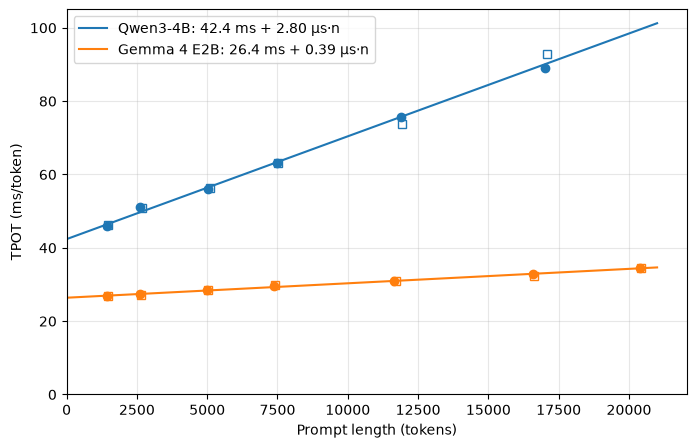

In [9]:
qa, qb = a, beta
cmp = pd.DataFrame({
    "Qwen3-4B": [qa * 1e3, qb * 1e6, W / 1e9, KV / 1024, (qa + qb * 1425) * 1e3, (qa + qb * 17000) * 1e3],
    "Gemma 4 E2B": [g_a * 1e3, g_beta * 1e6, G_W / 1e9, G_KV / 1024, (g_a + g_beta * 1425) * 1e3, (g_a + g_beta * 17000) * 1e3],
}, index=["a (ms)", "β (µs/token)", "weights read (GB)", "KV read (KiB/token)", "TPOT at 1.4k (ms)", "TPOT at 17k (ms)"])
cmp["ratio"] = cmp["Qwen3-4B"] / cmp["Gemma 4 E2B"]

x = np.linspace(0, 21000, 100)
fig, ax = plt.subplots(figsize=(8, 5))
for name, (a_, b_), t in [("Qwen3-4B", (qa, qb), both), ("Gemma 4 E2B", (g_a, g_beta), g_both)]:
    line, = ax.plot(x, (a_ + b_ * x) * 1e3, label=f"{name}: {a_ * 1e3:.1f} ms + {b_ * 1e6:.2f} µs·n")
    for tk, mk in [("WMT", "o"), ("AMZN", "s")]:
        s = t[t.ticker == tk]
        ax.plot(s.n, s.tpot_ms, mk, color=line.get_color(), mfc="none" if tk == "AMZN" else None)
ax.set(xlabel="Prompt length (tokens)", ylabel="TPOT (ms/token)", xlim=(0, None), ylim=(0, None))
ax.grid(alpha=0.3)
ax.legend()
cmp.round(2)

### Why Gemma 4 E2B decodes faster

Decode is memory-bandwidth-bound: TPOT ≈ bytes read per step / bandwidth. Both models read weights at ~50 GB/s, so the speedup is the ratio of bytes read.

**1. Fewer weight bytes: 1.31 vs 2.1 GB per step (a ratio 1.6×).**
- Hidden size 1536 vs 2560: every matrix is smaller.
- Per-layer embeddings (1.32 GB, half the file) are looked up, one row per layer per step, not read in full.
- 1 KV head vs 8: small K/V projections.
- Layers 15–34 have no K/V projections (they reuse earlier layers' KV). Their MLPs are double-wide (12288), which offsets part of the saving.

**2. Less KV read: 14 vs 144 KiB per context token (β ratio 7×; bytes ratio 10×).**
- 1 KV head vs 8.
- 7 of 35 layers attend over the full context; the other 28 use a 512-token sliding window, fixed for n > 512.
- Qwen3-4B reads all 36 layers × 8 KV heads at full length.
- Gemma's KV read runs at ~36 GB/s vs ~53 GB/s for Qwen3-4B, so β is 7× smaller rather than 10×.

Weights dominate the bytes at short context, the KV cache at long context. Speedup: 1.7× at 1.4k tokens, 2.7× at 17k, growing with n.

Not from prefill trimming: layers 15–34 are skipped only for prompt positions in prefill; decode runs all 35 layers per token. Not from compute: decode is matrix × vector, each weight used once per load.

## Notes: run-to-run variation

Apple M1 iMac, 8 GB. Both tickers were also run on 2026-11-06 at noise 50, 200 and 500, same settings. Change from that run to the one above:

| Ticker | Noise | TPOT (ms) | Change | Intercept change |
|---|---|---|---|---|
| WMT | 50 | 46.18 → 46.05 | −0.3% | +0.05% |
| WMT | 200 | 55.04 → 55.94 | +1.6% | −0.09% |
| WMT | 500 | 74.87 → 75.69 | +1.1% | −0.02% |
| AMZN | 50 | 46.37 → 46.35 | 0.0% | +0.01% |
| AMZN | 200 | 55.61 → 56.32 | +1.3% | −0.12% |
| AMZN | 500 | 73.82 → 73.74 | −0.1% | +0.02% |

- Prefill reproduces within 0.12%: compute-bound, stable day to day.
- TPOT reproduces within 0–1.6%. The largest changes are ~2 standard errors: within-run error bars understate day-to-day variation. Decode is memory-bandwidth-bound and more sensitive to machine state.
- No consistent direction: both tickers are higher at 200; at 500 WMT is higher and AMZN unchanged. Drift, not a systematic shift.
- Fitted line is stable: 42.1 ms + 2.70 µs·n (2026-11-06, 3 levels) vs 42.4 ms + 2.80 µs·n (above, 6 levels × 2 tickers).

## TODO

- Concurrency > 1: batched decode amortises the weight read across requests.